# The trajectory-angle map (log *s*, α) with lenscape — tutorial, part 2

The first tutorial (`tutorial_first_map_research_note`) produced the Δχ² map over the lens separation and mass
ratio, panel (b) of our research note. This one makes the companion map over the lens separation and the
**trajectory angle α**, panel (d) — the map that shows how many distinct source trajectories explain the data.
We use the 1× map of the first tutorial as the starting point, which keeps the runtime short; the same calls work
on the 2× and 4× maps.

**Why a second map.** In a (log *s*, log *q*) map each point shows only the *best* trajectory angle at that
lens geometry. Degenerate solutions of planetary events often differ mainly in α (the source crosses the caustic
on different sides) at nearly the same *s* and *q*, so they sit on top of each other in the first map. Plotting
χ² against (log *s*, α) separates them. lenscape offers two versions:

* **all local minima in α** (`maps.alpha_minima`): at every lattice point, fits from many starting angles, and
  every distinct minimum is kept — this is how such maps are usually drawn in papers: one dot per solution;
* **the profile** (`maps.alpha_profile`): at every point of a (log *s*, α) grid, χ² minimised over *all* other
  parameters including *q* — a filled map with a value everywhere, as in panel (d).

Runtimes quoted are for a 16-core AMD Ryzen 9 7950X (32 threads).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import maps, figures

print("lenscape", lenscape.__version__)

lenscape 0.1.0


## 1. Data, starting model and the 1× map

Exactly as in the first tutorial: the photometry from the CSV and the best-fit model. The 1× map is loaded from
the file the first tutorial saved (`data/tutorial_map_1x.npz`, included in the repository); if you want to
recompute it, run that notebook first.

Data(2531 points, t 9630.85 .. 9874.29, sets {'KMTA22': 436, 'KMTC22': 1128, 'KMTS22': 722, 'MOA22': 245})
1x map: 50 x 49 points, lowest chi2 2445.5


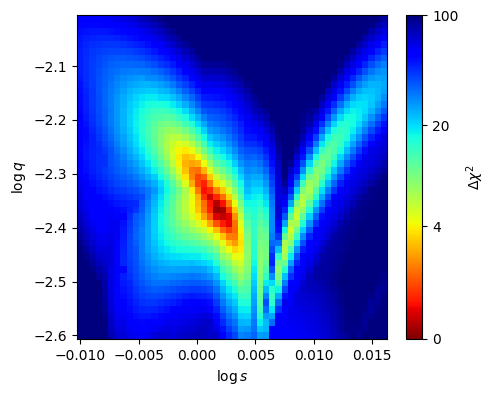

In [2]:
rows = np.genfromtxt("data/moa091_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)
sets = {}
for name in ["KMTA22", "KMTC22", "KMTS22", "MOA22"]:
    r = rows[rows["set"] == name]
    flux = 10 ** (-0.4 * (r["mag"] - 22.0))
    sets[name] = (r["t"], flux, flux * 0.4 * np.log(10) * r["mag_err"])
data = lenscape.Data.from_sets(sets)
best = np.array([9657.774, -0.026139, 34.593, 0.0021016, -2.37157, 4.40428, -2.98889])

map1 = dict(np.load("data/tutorial_map_1x.npz"))
logs1, logq1 = map1["logs"], map1["logq"]
print(data)
print(f"1x map: {map1['chi2'].shape[0]} x {map1['chi2'].shape[1]} points, lowest chi2 {map1['chi2_ref']:.1f}")
figures.plot_map(map1);

## 2. All local minima in the trajectory angle

`maps.alpha_minima` takes a map and, at every one of its lattice points, starts fits from `n_alpha` angles
spread over 0–2π (the other parameters from that point's solution). Every distinct minimum (angles differing by
more than `tol_alpha`) is kept. The result is an array with one row per minimum:
`(log s, log q, chi2, t0, u0, tE, alpha, log rho)`.

**Runtime on the 7950X for this step was about 22 minutes** (47 minutes on a 20-thread desktop).

In [3]:
t = time.time()
minima = maps.alpha_minima(map1, data, best=best)
print(f"wall time {(time.time() - t) / 60:.1f} min; {len(minima)} minima at {map1['chi2'].size} lattice points")


Stage 1/1: Trajectory-angle minima - 20 starting angles at each of 2450 points


wall time 47.4 min; 47190 minima at 2450 lattice points


**Plotting the minima.** A detail of the convention: a trajectory with impact parameter *u*₀ and angle α is the
same light curve as one with −*u*₀ and α + π (the lens system is point-symmetric), so a solution found with the
opposite sign of *u*₀ to the best fit is drawn at α + π. This puts both families on one axis, as in the
published maps.

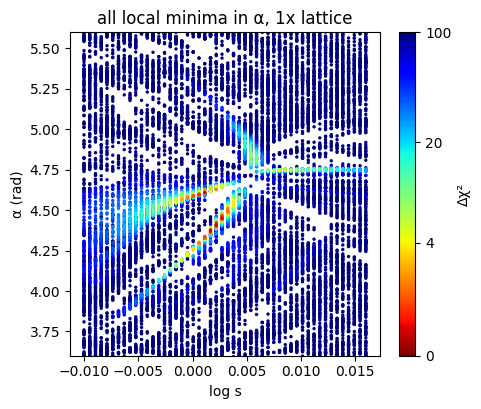

In [4]:
def plot_minima(rows, ref, u0_ref, vmax=100.0, ax=None):
    """log s against alpha for alpha_minima rows, colour = log10(Delta chi2 + 1) as figures.plot_map."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.2))
    d = rows[:, 2] - ref
    al = np.mod(rows[:, 6] + np.where(np.sign(rows[:, 4]) != np.sign(u0_ref), np.pi, 0.0), 2 * np.pi)
    o = np.argsort(-d)                                     # best on top
    sc = ax.scatter(rows[o, 0], al[o], c=np.log10(np.clip(d[o], 0, None) + 1), s=6, cmap="jet_r",
                    vmin=0, vmax=np.log10(vmax + 1), linewidths=0)
    cb = plt.colorbar(sc, ax=ax, ticks=np.log10(np.array([0, 4, 20, 100]) + 1))
    cb.set_ticklabels(["0", "4", "20", "100"]); cb.set_label("Δχ²")
    ax.set_xlabel("log s"); ax.set_ylabel("α (rad)")
    return ax

ref = min(map1["chi2_ref"], minima[:, 2].min())
ax = plot_minima(minima, ref, u0_ref=best[1])
ax.set_ylim(3.6, 5.6); ax.set_title("all local minima in α, 1x lattice");

Every lattice point contributes one or more dots: the main family of solutions runs along a curved track, and a
second track above it (around α ≈ 4.7–5.0) holds the solutions where the source passes the caustic on the other
side. The published Fig. 2 (right panel) shows the same two tracks.

## 3. The profile: a filled (log *s*, α) map

`maps.alpha_profile` fits every point of a (log *s*, α) grid, minimising over the remaining parameters — here
including log *q*, which is free. It starts each point from the nearest known solutions of the maps you pass in
(`[map1, minima]`: the lattice solutions and the angle minima; the minima matter, because the lattice alone knows
only the best angle at each point), then runs the same neighbour refinement as the lattice maps. The α grid below
has the paper's step of 0.016 rad.

**Runtime on the 7950X for this step was about 40 minutes** (91 minutes on a 20-thread desktop).

In [5]:
alphas = np.arange(3.6, 5.6 + 1e-9, 0.016)

t = time.time()
prof = maps.alpha_profile([map1, minima], data, logs1, alphas, best=best)
print(f"wall time {(time.time() - t) / 60:.1f} min; grid {prof['chi2'].shape}, lowest chi2 {prof['chi2_ref']:.1f}")


Stage 1/2: Fits at fixed (log s, alpha) - 6300 points from the 3 nearest of 49640 known solutions



Stage 2/2: Neighbour refinement - refit points whose neighbours found a better solution


neighbour refinement: 17665 points checked, 7272 improved (1576 by less than 1)
done in 5474s; lowest chi2 2445.64
wall time 91.2 min; grid (50, 126), lowest chi2 2445.6


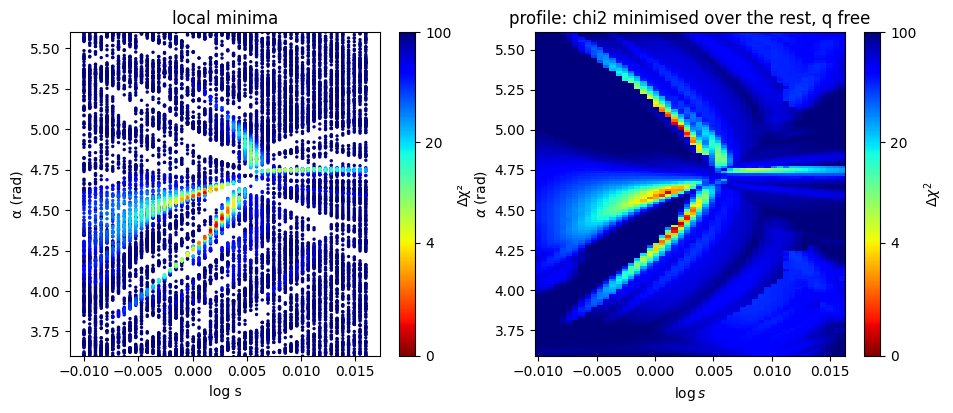

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
plot_minima(minima, ref, u0_ref=prof["u0_ref"], ax=ax[0]); ax[0].set_ylim(3.6, 5.6); ax[0].set_title("local minima")
figures.plot_map(prof, ax=ax[1], chi2_ref=ref); ax[1].set_title("profile: chi2 minimised over the rest, q free");

The profile fills the plane: between the tracks of the minima it shows how much worse the intermediate angles
are, and the tracks themselves become continuous valleys. This is the version used for panel (d) of the research
note, computed there on the 8× lattice (393 × 381 points).

Two options worth knowing: `one_sign=True` draws each solution once (the mirrored family is folded onto its
partner, as in codes that keep *u*₀ > 0), and `u0_ref` fixes which sign of *u*₀ is counted at the plotted α
when you pass several maps whose best solutions have different signs.

## 4. Saving

The minima are a plain array, the profile a dictionary like the lattice maps.

In [7]:
np.savez("data/tutorial_alpha_1x.npz", minima=minima, logs=prof["logs"], alphas=prof["alphas"], chi2=prof["chi2"],
         pars=prof["pars"], chi2_ref=prof["chi2_ref"], u0_ref=prof["u0_ref"])
print("saved data/tutorial_alpha_1x.npz")

saved data/tutorial_alpha_1x.npz


Finer versions: pass the 2× or 4× maps of the first tutorial (`[map4, map2, map1, minima]`) and a finer
`logs`/`alphas` grid; `alpha_profile` starts from whatever solutions it is given, so a coarse profile can be
passed in as well to seed a finer one (`[prof, map4, minima]`).